In [1]:
import pandas as pd
df = pd.read_csv("IGCC_Uncertainty_dataset.csv")

In [2]:
df

,Ambient Air Temperature (Dry Bulb Average) (°F),As-Delivered Coal Cost ($/ton),CO2 Removal Efficiency (%),Power Requirement (% MWg),Cooling Water Temperature Drop (°F),Plant Outputs: Captured CO2: Flow Rate (tons/hr),Performance Parameter: Net Electrical Output (MW),Costs of CO2 Avoided & Captured: Cost of CO2 Captured ($/ton)
0,65.849998,58.299999,60.787498,8.295,28.900000,350.925293,566.327698,206.435303
1,80.550003,55.700001,85.112503,9.285,25.500000,463.870056,518.344238,150.798462
2,64.949997,62.900002,62.187500,6.435,47.299999,358.609619,578.199097,203.933243
3,37.950001,48.700001,86.512497,9.015,11.700000,496.849060,547.814941,144.885849
4,69.150002,31.500000,63.937500,6.495,37.500000,365.735321,572.414734,179.622055
...,...,...,...,...,...,...,...,...
195,32.549999,58.700001,69.362503,7.215,38.099998,411.700623,586.113220,179.689514
196,64.050003,51.099998,84.762497,9.555,41.500000,472.210388,528.255981,147.134338
197,43.650002,68.699997,65.512497,8.955,40.900002,385.882538,570.839600,196.145859
198,34.049999,49.900002,62.537498,11.565,17.900000,374.430664,562.361938,194.301773


In [3]:
df.isna().sum()

Ambient Air Temperature (Dry Bulb Average) (°F)                  0
As-Delivered Coal Cost ($/ton)                                   0
CO2 Removal Efficiency (%)                                       0
Power Requirement (% MWg)                                        0
Cooling Water Temperature Drop (°F)                              0
Plant Outputs: Captured CO2: Flow Rate (tons/hr)                 0
Performance Parameter: Net Electrical Output (MW)                0
Costs of CO2 Avoided & Captured: Cost of CO2 Captured ($/ton)    0
dtype: int64

In [4]:
df.duplicated().sum()

np.int64(0)

In [5]:
x = df[['Ambient Air Temperature (Dry Bulb Average) (°F)',
    'As-Delivered Coal Cost ($/ton)',
    'CO2 Removal Efficiency (%)',
    'Power Requirement (% MWg)',
    'Cooling Water Temperature Drop (°F)']]

y = df['Plant Outputs: Captured CO2: Flow Rate (tons/hr)']

In [6]:
x

,Ambient Air Temperature (Dry Bulb Average) (°F),As-Delivered Coal Cost ($/ton),CO2 Removal Efficiency (%),Power Requirement (% MWg),Cooling Water Temperature Drop (°F)
0,65.849998,58.299999,60.787498,8.295,28.900000
1,80.550003,55.700001,85.112503,9.285,25.500000
2,64.949997,62.900002,62.187500,6.435,47.299999
3,37.950001,48.700001,86.512497,9.015,11.700000
4,69.150002,31.500000,63.937500,6.495,37.500000
...,...,...,...,...,...
195,32.549999,58.700001,69.362503,7.215,38.099998
196,64.050003,51.099998,84.762497,9.555,41.500000
197,43.650002,68.699997,65.512497,8.955,40.900002
198,34.049999,49.900002,62.537498,11.565,17.900000


In [7]:
y

0      350.925293
1      463.870056
2      358.609619
3      496.849060
4      365.735321
          ...    
195    411.700623
196    472.210388
197    385.882538
198    374.430664
199    424.465302
Name: Plant Outputs: Captured CO2: Flow Rate (tons/hr), Length: 200, dtype: float64

In [8]:
from sklearn.model_selection import GridSearchCV, train_test_split, RandomizedSearchCV
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from xgboost import XGBRegressor
from sklearn.ensemble import GradientBoostingRegressor

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

print("\n=== SHAP MODEL ===\n")


=== SHAP MODEL ===



In [9]:
# XGBoost Regressor
xgb_grid = GridSearchCV(
    XGBRegressor(random_state=42),
    {
        "n_estimators": [100, 300],
        "max_depth": [3, 6, 10],
        "learning_rate": [0.01, 0.1, 0.3],
        "subsample": [0.8, 1.0],
        "colsample_bytree": [0.8, 1.0]
    },
    cv=5, scoring="r2", n_jobs=-1
)
xgb_grid.fit(x_train, y_train)

best_xgb = xgb_grid.best_estimator_
print("XGBoost best params:", xgb_grid.best_params_)
print('Train R2:',best_xgb.score(x_train,y_train))
print('Test R2:',best_xgb.score(x_test,y_test))

XGBoost best params: {'colsample_bytree': 1.0, 'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 300, 'subsample': 0.8}
Train R2: 0.9999869295953676
Test R2: 0.9928623608178583


In [10]:
#Checking the RMSE and MAPE scores
from sklearn.metrics import mean_squared_error
import numpy as np

print("\n=== RMSE & MAPE ===\n")

models = {
    'XGBoost':           best_xgb
}

for name, model in models.items():
    y_pred = model.predict(x_test)
    rmse   = np.sqrt(mean_squared_error(y_test, y_pred))
    mape   = np.mean(np.abs((y_test - y_pred) / y_test)) * 100
    print(f"{name} | RMSE: {rmse:.4f} | MAPE: {mape:.4f}%")


=== RMSE & MAPE ===

XGBoost | RMSE: 4.7787 | MAPE: 0.8198%


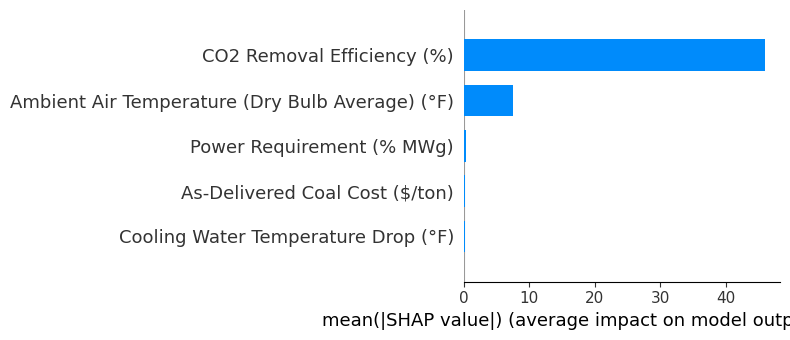

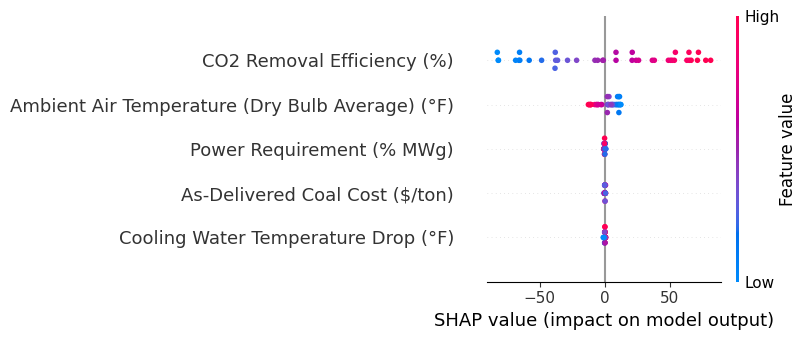

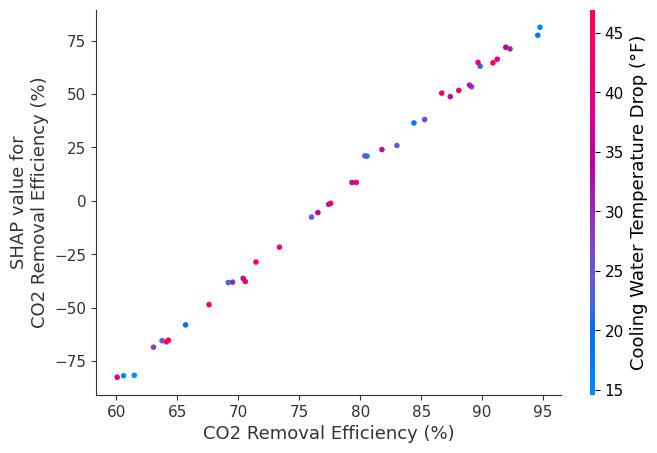

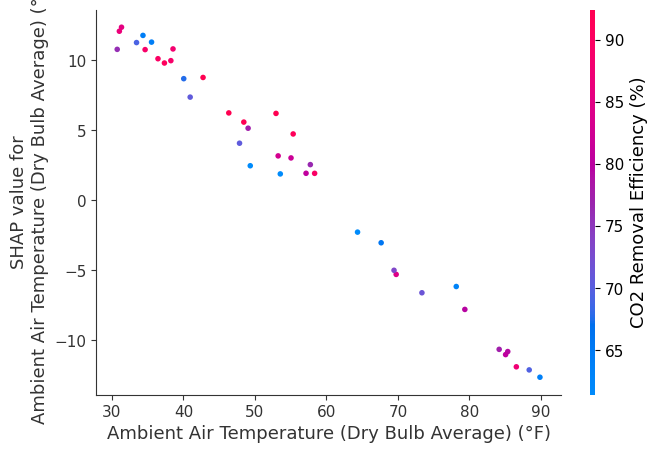

In [11]:
import shap, numpy as np
explainer   = shap.TreeExplainer(best_xgb)
shap_values = explainer.shap_values(x_test)

shap.summary_plot(shap_values, x_test, plot_type="bar")
shap.summary_plot(shap_values, x_test)

mean_abs = np.abs(shap_values).mean(axis=0)
order    = np.argsort(mean_abs)[::-1]
for i in order[:2]:
    shap.dependence_plot(x_test.columns[i], shap_values, x_test)